# 🏛️ UNIVERSIDAD NACIONAL DE SAN ANTONIO ABAD DEL CUSCO
### Facultad de Ingeniería Civil — Laboratorio de Materiales y Concreto
**Asignatura:** Tecnología de Materiales (IC151)  
**Docente:** ______________________________ | **Grupo / Brigada:** ______________________________  
**Semestre:** 2026-II  

---

# 🔬 PRÁCTICA N.° 11 (TM-11): Determinación del Contenido de Humedad en Madera Estructural
### Cuaderno Interactivo de Procesamiento y Control Normativo

> **Normativa Técnica Aplicable:**  
> **NTP 251.010:2020** | **ASTM D4442-20** | **RNE E.010 Madera**

---

### 🎯 Objetivos de la Práctica
1. Determinar el contenido de humedad porcentual por secado en horno a 103 ± 2 °C hasta masa constante.
2. Contrastar la madera evaluada frente al límite máximo reglamentario del RNE E.010 (<= 22 %).
3. Relacionar el estado higroscópico con la humedad de equilibrio de la región Cusco (~12 %–14 %).

## ⚙️ 1. Conexión con el Motor de Cálculo (`civillab_unsaac`)
Presiona **Ejecutar (▶)** en la siguiente celda antes de comenzar. Conecta las fórmulas normativas de la UNSAAC, tablas y graficadores.

In [ ]:
# CIVILLAB_WEB_PRELOAD: prepara el navegador (solo versión web)
%pip install -q openpyxl


In [1]:
# ==============================================================================
# CONEXIÓN CON LA LIBRERÍA DEL LABORATORIO (Ejecutar primero, no modificar)
# ==============================================================================
try:
    import civillab_unsaac as lab
except ModuleNotFoundError:
    # Si la librería aún no está instalada, la ubicamos automáticamente en el proyecto
    import sys
    from pathlib import Path
    raices = [
        Path.cwd(),
        *list(Path.cwd().parents)[:3],
        Path.cwd() / "08_SOFTWARE_LABORATORIO",
        Path.cwd() / "0003_UNSAAC_DOCENCIA" / "08_SOFTWARE_LABORATORIO",
    ]
    for r in raices:
        if (r / "civillab_unsaac").is_dir():
            sys.path.insert(0, str(r))
            break
    import civillab_unsaac as lab

from pathlib import Path
from civillab_unsaac import *
import matplotlib
try:
    get_ipython()
except NameError:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

try:
    from IPython.display import display
except ImportError:
    display = print

# Carpeta limpia para gráficos y fichas Excel de salida
_pkg_root = Path(lab.__file__).resolve().parents[1]
DIR_SALIDA = (_pkg_root / "fichas_generadas") if (_pkg_root / "notebooks").is_dir() else (Path.cwd() / "fichas_generadas")
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

print("✓ Suite CivilLab UNSAAC conectada y lista para calcular.")

✓ Suite CivilLab UNSAAC conectada y lista para calcular.


---
## 🪵 2. Ingreso de Datos, Diagnóstico y Gráfico RNE E.010


=== EVALUACIÓN DE HUMEDAD EN MADERA (NTP 251.010 / RNE E.010) ===
Especie: Eucalipto (Eucalyptus globulus) | Procedencia: Valle del Cusco
Uso previsto: Estructural aserrada | Probetas ensayadas: 3
• Contenido de humedad promedio: 14.48 %
• Contenido de humedad máximo:   14.73 %
• Requisito RNE E.010: Máximo 22 % (Madera estructural aserrada)

DICTAMEN NORMATIVO: APROBADO — APTA PARA USO ESTRUCTURAL


,codigo,masa_humeda_g,masa_seca_g,agua_evaporada_g,contenido_humedad_porc
0,MAD-01,128.5,112.0,16.5,14.73
1,MAD-02,135.2,118.4,16.8,14.19
2,MAD-03,142.0,124.0,18.0,14.52


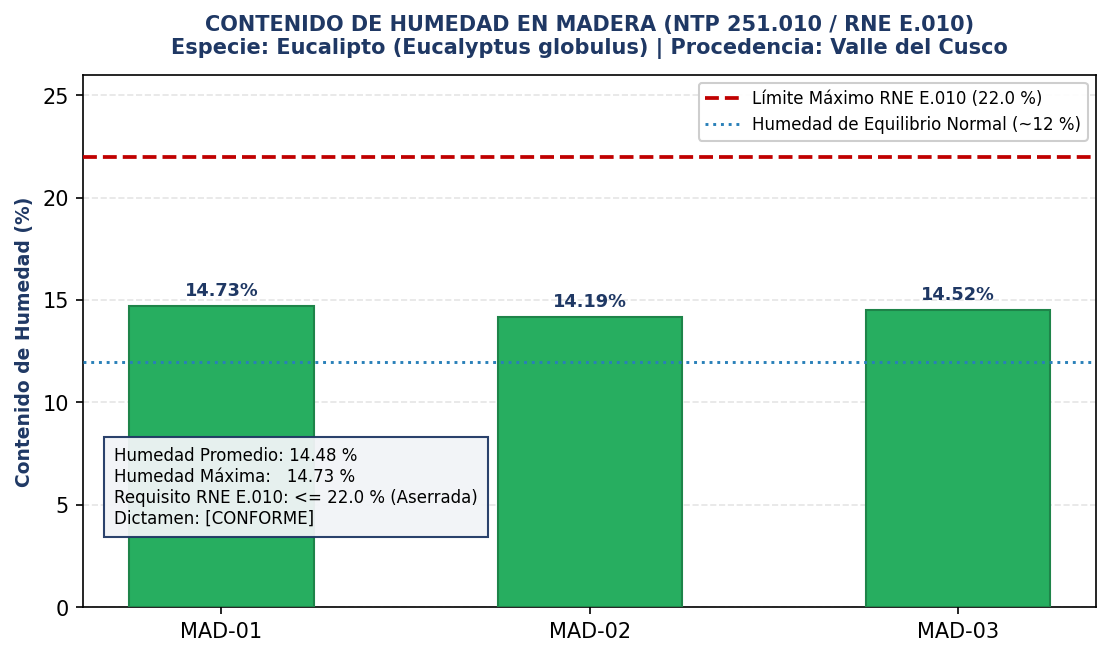

In [2]:
probetas_madera = [
    {"codigo": "MAD-01", "masa_humeda_g": 128.5, "masa_seca_g": 112.0},
    {"codigo": "MAD-02", "masa_humeda_g": 135.2, "masa_seca_g": 118.4},
    {"codigo": "MAD-03", "masa_humeda_g": 142.0, "masa_seca_g": 124.0},
]

madera = HumedadMadera(
    probetas=probetas_madera,
    especie="Eucalipto (Eucalyptus globulus)",
    procedencia="Valle del Cusco",
    uso_previsto="Estructural aserrada",
)

display(madera.df)
print("\n" + madera.diagnostico_tecnico())
graficar_humedad_madera(madera, guardar_ruta=DIR_SALIDA / "TM-11_Humedad_Madera.png", mostrar=True)

---
## 📝 3. Conclusiones